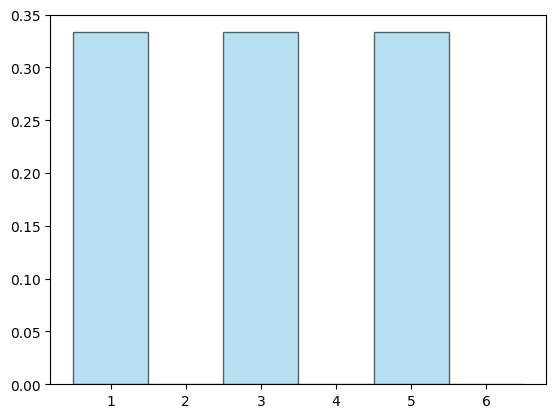

In [69]:
#@title Ejemplo del dado { run: "auto" }

import numpy as np
import matplotlib.pyplot as plt

def roll_dice(num_rolls):
    continuous_samples = np.random.uniform(0, 1, num_rolls)
    dice_rolls = np.ceil(continuous_samples * 6).astype(int)
    return dice_rolls

number_of_samples = 3 # @param {type:"integer"}
samples = roll_dice(number_of_samples)

plt.hist(samples, bins=np.arange(0.5, 7.5, 1), density=True, alpha=0.6, color='skyblue', edgecolor='black')
plt.show()

-1.046089078631589


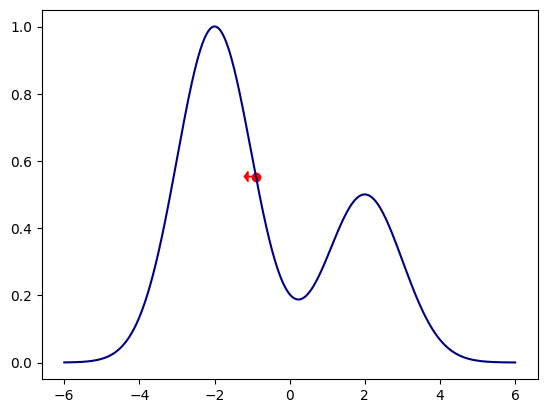

In [83]:
#@title Ejemplo continuo { run: "auto" }

def target_pdf(x):
    return np.exp(-0.5 * (x + 2)**2) + 0.5 * np.exp(-0.5 * (x - 2)**2)

def score_function(x):
    p = target_pdf(x)
    grad = -(x + 2) * np.exp(-0.5 * (x + 2)**2) - 0.5 * (x - 2) * np.exp(-0.5 * (x - 2)**2)
    return grad / p

# Un solo punto para mayor simplicidad
x_test = -0.9  # @param {type:"slider", min:-6, max:6, step:0.1}
x_range = np.linspace(-6, 6, 500)
score_val = score_function(x_test)
y_val = target_pdf(x_test)
print(score_val)
plt.plot(x_range, target_pdf(x_range), label='Target PDF', color='navy')
plt.scatter(x_test, y_val, color='red')
plt.arrow(x_test, y_val, score_val * 0.2, 0, head_width=0.03, head_length=0.1, fc='red', ec='red')

plt.show()

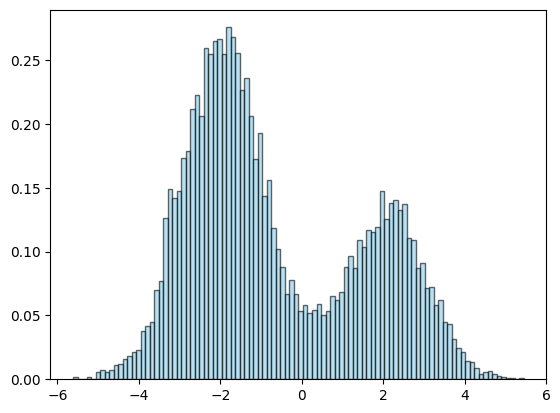

In [84]:
def langevin_sample(num_steps=1000, step_size=0.1):
    x = 0.0
    history = [x]

    for _ in range(num_steps):
        gradient_term = step_size * score_function(x)
        noise_term = np.sqrt(2 * step_size) * np.random.normal(0, 1)
        x = x + gradient_term + noise_term
        history.append(x)

    return np.array(history)

number_of_samples = 10000 # @param {type:"integer"}
samples = langevin_sample(num_steps=number_of_samples, step_size=0.1)

plt.hist(samples, bins=100, density=True, alpha=0.6, color='skyblue', label='Muestras Langevin', edgecolor='black')
plt.show()

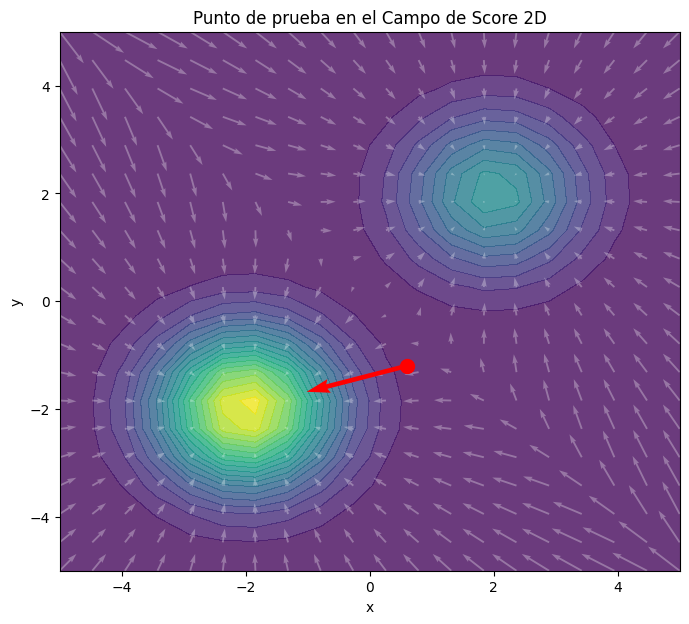

In [87]:
import numpy as np
import matplotlib.pyplot as plt

#@title Vista 2D con Punto de Prueba { run: "auto" }
x_test_2d = 0.6 # @param {type:"slider", min:-5, max:5, step:0.1}
y_test_2d = -1.2 # @param {type:"slider", min:-5, max:5, step:0.1}

def target_pdf_2d(x, y):
    p1 = np.exp(-0.5 * ((x + 2)**2 + (y + 2)**2))
    p2 = 0.5 * np.exp(-0.5 * ((x - 2)**2 + (y - 2)**2))
    return p1 + p2

def score_function_2d(x, y):
    p = target_pdf_2d(x, y)
    grad_x = -(x + 2) * np.exp(-0.5 * ((x + 2)**2 + (y + 2)**2)) - 0.5 * (x - 2) * np.exp(-0.5 * ((x - 2)**2 + (y - 2)**2))
    grad_y = -(y + 2) * np.exp(-0.5 * ((x + 2)**2 + (y + 2)**2)) - 0.5 * (y - 2) * np.exp(-0.5 * ((x - 2)**2 + (y - 2)**2))
    return grad_x / p, grad_y / p

x = np.linspace(-5, 5, 20)
y = np.linspace(-5, 5, 20)
X, Y = np.meshgrid(x, y)
Z = target_pdf_2d(X, Y)
U, V = score_function_2d(X, Y)

plt.figure(figsize=(8, 7))
plt.contourf(X, Y, Z, levels=20, cmap='viridis', alpha=0.8)
plt.quiver(X, Y, U, V, color='white', alpha=0.3)

# Resaltar punto de prueba y su vector de score
s_x, s_y = score_function_2d(x_test_2d, y_test_2d)
plt.scatter(x_test_2d, y_test_2d, color='red', s=100, zorder=5)
plt.quiver(x_test_2d, y_test_2d, s_x, s_y, color='red', scale=15, zorder=6)

plt.title('Punto de prueba en el Campo de Score 2D')
plt.xlabel('x')
plt.ylabel('y')
plt.show()

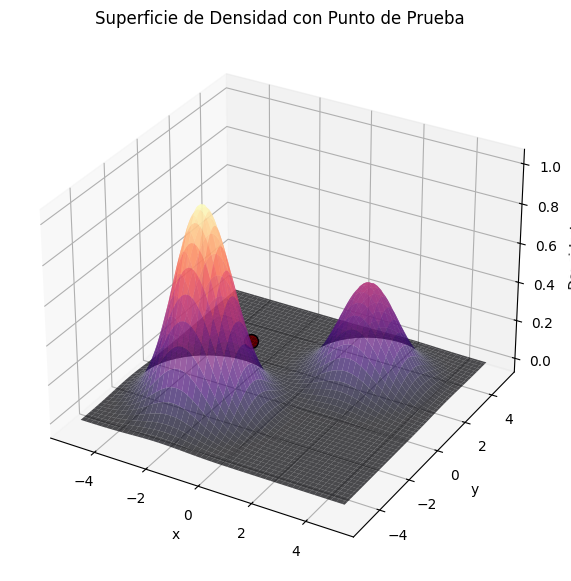

In [90]:
from mpl_toolkits.mplot3d import Axes3D

#@title Vista 3D con Punto de Prueba { run: "auto" }
x_p = -0.8 # @param {type:"slider", min:-5, max:5, step:0.1}
y_p = -1 # @param {type:"slider", min:-5, max:5, step:0.1}

x_fine = np.linspace(-5, 5, 100)
y_fine = np.linspace(-5, 5, 100)
Xf, Yf = np.meshgrid(x_fine, y_fine)
Zf = target_pdf_2d(Xf, Yf)

z_p = target_pdf_2d(x_p, y_p)

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
surf = ax.plot_surface(Xf, Yf, Zf, cmap='magma', edgecolor='none', alpha=0.7)

# Dibujar el punto sobre la superficie
ax.scatter([x_p], [y_p], [z_p], color='red', s=100, label='Test Point', edgecolors='black')

ax.set_title('Superficie de Densidad con Punto de Prueba')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('Densidad')
plt.show()